<a href="https://colab.research.google.com/github/rahul-kothari/transparent-obj-detection/blob/main/Mask_RCNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

https://colab.research.google.com/github/navidyou/Mask-RCNN-implementation-for-cell-nucleus-detection-executable-on-google-colab-/blob/master/mask_RCNN_cell_nucleus_google_colab.ipynb#scrollTo=EMwapxaFSZIH

https://github.com/matterport/Mask_RCNN/blob/master/samples/balloon/balloon.py

https://machinelearningmastery.com/how-to-train-an-object-detection-model-with-keras/

Try with already downloaded dataset!

```
COMP 592 - Transparent Object Detection
Rahul Kothari
Student ID: 201316606
University of Liverpool, 2021
```
Mask R-CNN Transfer Learning

# Instructions
**You are required to mount this file to your google drive.**
1. You will be asked to provide the path to your main directory in google drive where data and other files are stored (explained below).
```
MAIN DIRECTORY
  | Data
     | train
        | Glass(24).jpg
        | ...
        | region_data_train.json
     | val
        | Glass(41).jpg
        | ...
        | region_data_val.json
  | logs
     | mask
        | transparentobj20210407T1018
            | mask_rcnn_transparentobj_0001.h5
            | mask_rcnn_transparentobj_0002.h5
            | ...
            | mask_rcnn_transparentobj_0040.h5
     | vgg
  | config.py
  | utils.py
  | model.py
  | visualize.py
  | mask_rcnn_coco.h5
```
2. You need the dataset + its annotation and must store it in the format shown above.
3. You will also need 4 files that define MRCNN code. It is taken from the  `Mask RCNN github repo/mrcnn directory` with some changes (to import statements):
  - `config.py`
  - `utils.py`
  - `model.py`
  - `visualize.py`
*These files are also uploaded to my github! You may copy from there!*
4. If you have it, upload pre trained weights of the mask rcnn model - `mask_rcnn_coco.h5`. Upload it to the parent directory within gDrive
5. If you don't want to train just play with my transfer-learnt model, upload the weights to `logs/mask/transparentobj20210407T1018`. *The pre-trained model weights can be found on my github!* 

In [ ]:
%tensorflow_version 1.x


TensorFlow 1.x selected.


In [ ]:
#!pip install -q keras==2.3.1
import keras
print(keras.__version__)

Using TensorFlow backend.


2.3.1


- Add constants
- Move files to root directory for ease
- manage all imports

In [ ]:
# Copy required files to ROOT_DIR 

!cp /content/drive/MyDrive/Colab\ Notebooks/COMP592_Transaprent_Obj_Detection/*.py .
!cp /content/drive/MyDrive/Colab\ Notebooks/COMP592_Transaprent_Obj_Detection/mask_rcnn_coco.h5 .

In [ ]:
import os
import sys
import random
import math
import re
import time
import numpy as np
import cv2
import matplotlib
import matplotlib.pyplot as plt
import json
import pandas as pd

from skimage.io import imread, imshow, imread_collection, concatenate_images
from skimage.transform import resize
import skimage.draw

import config, utils, visualize, model
from config import Config
import model as modellib
from model import log

%matplotlib inline 

In [ ]:
# Some constants:
ROOT_DIR = os.getcwd() # /content folder in gdrive.
user_specified_location = input("Enter your google drive directory where data is hosted and where model will be stored. e.g. \"Colab Notebooks/COMP592_Transaprent_Obj_Detection\":") 
GDRIVE_FOLDER_PATH = os.path.join(ROOT_DIR, "drive/MyDrive", user_specified_location")
DATASET_DIR = os.path.join(GDRIVE_FOLDER_PATH, "data")

# Directory to save logs and trained model
MODEL_DIR = os.path.join(GDRIVE_FOLDER_PATH, "logs", "mask")

# Class the model is trained on
CLASS_NAME = "transparentObject"

# Local path to trained weights file
COCO_MODEL_PATH = os.path.join(GDRIVE_FOLDER_PATH, "mask_rcnn_coco.h5")
# Download COCO trained weights from Releases if needed
if not os.path.exists(COCO_MODEL_PATH):
  utils.download_trained_weights(COCO_MODEL_PATH)

# Configuration


In [ ]:
class ObjectConfig(Config):
    """Configuration for training on the dataset.
    Derives from the base Config class and overrides values specific
    to the dataset.
    """
    # Give the configuration a recognizable name
    NAME = "transparentObj"

    # Train on 1 GPU and 2 images per GPU (A 12GB GPU can typically
    # handle 2 images of 1024x1024px.).
    # Batch size is (GPUs * images/GPU). 
    GPU_COUNT = 1
    IMAGES_PER_GPU = 2

    # Number of classes (including background)
    NUM_CLASSES = 1 + 1  # background + object

    # number of epoch
    EPOCHS = 40

    # Number of training steps per epoch
    STEPS_PER_EPOCH = 200


    
config = ObjectConfig()
#config.display()

# Data

* Create Dataset class
* Load the data
* Visualise and inspect the masks

In [ ]:
class ObjectDataset(utils.Dataset):

    def load_object(self, mode):
        # Load a subset of the transparentObject dataset.
        # mode: mode to load: train or val

        # Background class is already added.
        self.add_class(CLASS_NAME, 1, CLASS_NAME)

        # Train or validation dataset?
        assert mode in ["train", "val", "test"]
        dataset_dir = os.path.join(DATASET_DIR, mode)

        # Load annotations
        # VGG Image Annotator (up to version 1.6) saves each image in the form:
        # { 'filename': '28503151_5b5b7ec140_b.jpg',
        #   'regions': {
        #       '0': {
        #           'region_attributes': {},
        #           'shape_attributes': {
        #               'all_points_x': [...],
        #               'all_points_y': [...],
        #               'name': 'polygon'}},
        #       ... more regions ...
        #   },
        #   'size': 100202
        # }
        annotation_file_path = os.path.join(dataset_dir, "region_data_"+mode+".json")
        annotations = json.load(open(annotation_file_path))
        if type(annotations) == dict:
          annotations = list(annotations.values())
        elif type(annotations) != list:
          raise TypeError("annotations must be of type dict or list")
        # else -> type == list.

        # Skip unannotated images.
        annotations = [a for a in annotations if a['regions']]

        if mode == "test":
          dataset_dir = os.path.join(DATASET_DIR, "val")

        # Add images
        for a in annotations:
            # Get the x, y coordinaets of points of the polygons that make up
            # the outline of each object instance. These are stored in the
            # shape_attributes (see json format above)
            # The if condition is needed to support VIA versions 1.x and 2.x.
            if type(a['regions']) is dict:
                polygons = [r['shape_attributes'] for r in a['regions'].values()]
            else:
                polygons = [r['shape_attributes'] for r in a['regions']] 

            # load_mask() needs the image size to convert polygons to masks.
            image_path = os.path.join(dataset_dir, a['filename'])
            image = skimage.io.imread(image_path)
            height, width = image.shape[:2]

            self.add_image(CLASS_NAME,
                           image_id=a['filename'],  
                           path=image_path,
                           width=width, height=height,
                           polygons=polygons)

    def load_mask(self, image_id):
        """Generate instance masks for an image.
       Returns:
        masks: A bool array of shape [height, width, instance count] with
            one mask per instance.
        class_ids: a 1D array of class IDs of the instance masks.
        """
        # Convert polygons to a bitmap mask of shape [height, width, instance_count]
        info = self.image_info[image_id]
        mask = np.zeros([info["height"], info["width"], len(info["polygons"])],
                        dtype=np.uint8)
        for i, p in enumerate(info["polygons"]):
            # Get indexes of pixels inside the polygon and set them to 1 (and others to 0)
            rr, cc = skimage.draw.polygon(p['all_points_y'], p['all_points_x'])
            mask[rr, cc, i] = 1

        # Return mask, and array of class IDs of each instance. Since we have
        # one class ID only, we return an array of 1s
        return mask.astype(np.bool), np.ones([mask.shape[-1]], dtype=np.int32)

    def image_reference(self, image_id):
        """Return the path of the image."""
        info = self.image_info[image_id]
        if info["source"] == CLASS_NAME:
            return info["path"]
        else:
            super(self.__class__, self).image_reference(image_id)


In [ ]:
# Training dataset
dataset_train = ObjectDataset()
dataset_train.load_object("train")
dataset_train.prepare()

# Validation dataset
dataset_val = ObjectDataset()
dataset_val.load_object("val")
dataset_val.prepare()

print("Done loading training and validating data ...")

Done loading training and validating data ...


### Inspect Data

In [ ]:
dataset = dataset_train

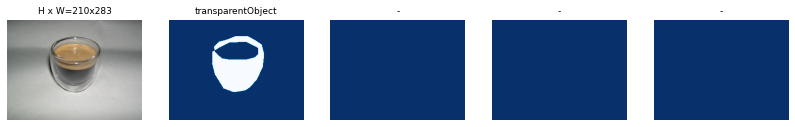

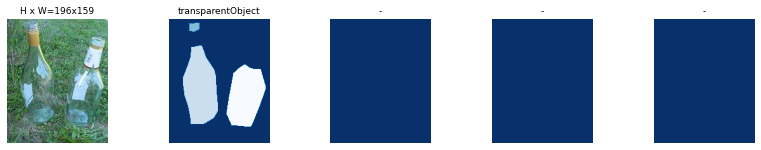

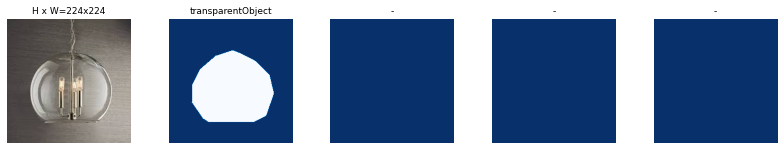

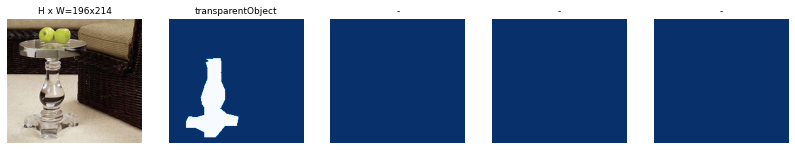

In [ ]:
# Load and display random samples
image_ids = np.random.choice(dataset.image_ids, 4)
for image_id in image_ids:
    image = dataset.load_image(image_id)
    mask, class_ids = dataset.load_mask(image_id)
    visualize.display_top_masks(image, mask, class_ids, dataset.class_names)

### Bounding Boxes
Rather than using bounding box coordinates provided by the source datasets, we compute the bounding boxes from masks instead. This allows us to handle bounding boxes consistently regardless of the source dataset, and it also makes it easier to resize, rotate, or crop images because we simply generate the bounding boxes from the updates masks rather than computing bounding box transformation for each type of image transformation.

image_id  63 /content/drive/MyDrive/Colab Notebooks/COMP592_Transaprent_Obj_Detection/data/train/Glass126.jpg
image                    shape: (225, 225, 3)         min:    0.00000  max:  255.00000  uint8
mask                     shape: (225, 225, 6)         min:    0.00000  max:    1.00000  bool
class_ids                shape: (6,)                  min:    1.00000  max:    1.00000  int32
bbox                     shape: (6, 4)                min:   13.00000  max:  216.00000  int32


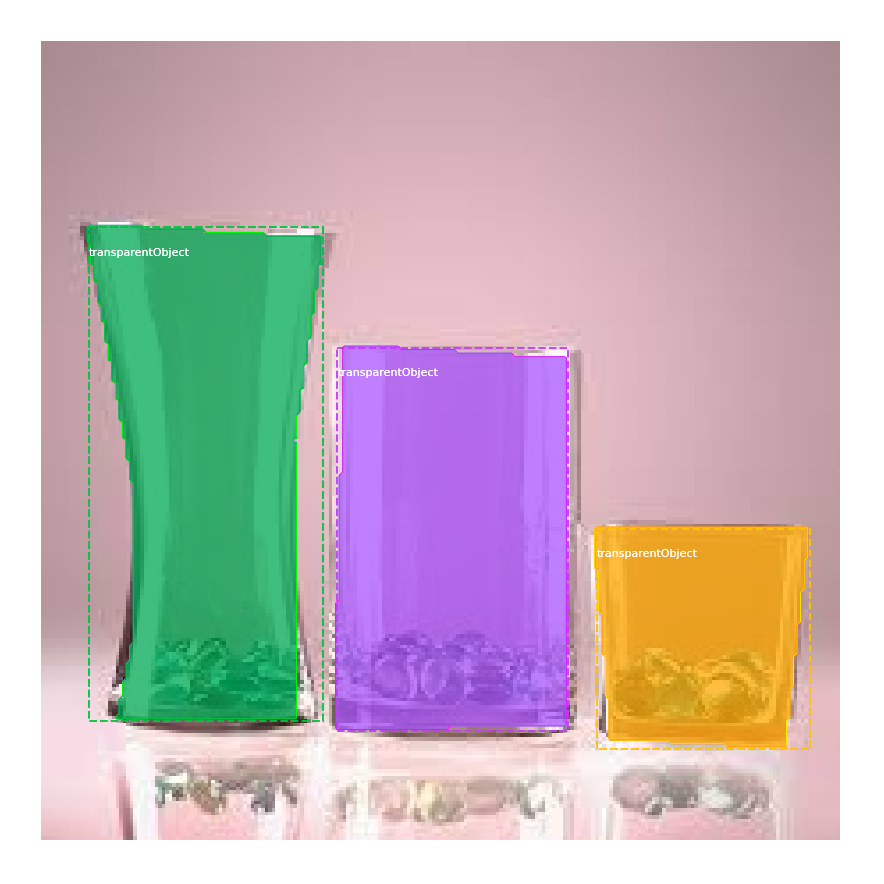

In [ ]:
# Load random image and mask.
image_id = random.choice(dataset.image_ids)
image = dataset.load_image(image_id)
mask, class_ids = dataset.load_mask(image_id)
# Compute Bounding box
bbox = utils.extract_bboxes(mask)

# Display image and additional stats
print("image_id ", image_id, dataset.image_reference(image_id))
log("image", image)
log("mask", mask)
log("class_ids", class_ids)
log("bbox", bbox)
# Display image and instances
visualize.display_instances(image, bbox, mask, class_ids, dataset.class_names)

# Create Model

In [ ]:
# Create model in training mode
model = modellib.MaskRCNN(mode="training", config=config, model_dir=MODEL_DIR)

In [ ]:
# Which weights to start with?
init_with = "coco"  # imagenet, coco, or last

if init_with == "imagenet":
  model.load_weights(model.get_imagenet_weights(), by_name=True)
elif init_with == "coco":
  # exclude layers that are different due to the different number of classes
  model.load_weights(COCO_MODEL_PATH, by_name=True, 
                     exclude=["mrcnn_class_logits", "mrcnn_bbox_fc", "mrcnn_bbox", "mrcnn_mask"])
elif init_with == "last": 
    # Load the last model you trained and continue training
    model.load_weights(model.find_last(), by_name=True)

print("Done loading weights for the model...")

Done loading weights for the model...


In [ ]:
# Passing layers="heads" freezes all layers except the head layers.
model.train(dataset_train, dataset_val,
            learning_rate=config.LEARNING_RATE,
            epochs=config.EPOCHS,
            layers='heads')


Starting at epoch 20. LR=0.001

Checkpoint Path: /content/drive/MyDrive/Colab Notebooks/COMP592_Transaprent_Obj_Detection/logs/mask/transparentobj20210407T1018/mask_rcnn_transparentobj_{epoch:04d}.h5
Selecting layers to train
fpn_c5p5               (Conv2D)
fpn_c4p4               (Conv2D)
fpn_c3p3               (Conv2D)
fpn_c2p2               (Conv2D)
fpn_p5                 (Conv2D)
fpn_p2                 (Conv2D)
fpn_p3                 (Conv2D)
fpn_p4                 (Conv2D)
In model:  rpn_model
    rpn_conv_shared        (Conv2D)
    rpn_class_raw          (Conv2D)
    rpn_bbox_pred          (Conv2D)
mrcnn_mask_conv1       (TimeDistributed)
mrcnn_mask_bn1         (TimeDistributed)
mrcnn_mask_conv2       (TimeDistributed)
mrcnn_mask_bn2         (TimeDistributed)
mrcnn_class_conv1      (TimeDistributed)
mrcnn_class_bn1        (TimeDistributed)
mrcnn_mask_conv3       (TimeDistributed)
mrcnn_mask_bn3         (TimeDistributed)
mrcnn_class_conv2      (TimeDistributed)
mrcnn_class_bn2    

/tensorflow-1.15.2/python3.7/tensorflow_core/python/framework/indexed_slices.py:424: UserWarning: Converting sparse IndexedSlices to a dense Tensor of unknown shape. This may consume a large amount of memory.
  "Converting sparse IndexedSlices to a dense Tensor of unknown shape. "
/tensorflow-1.15.2/python3.7/tensorflow_core/python/framework/indexed_slices.py:424: UserWarning: Converting sparse IndexedSlices to a dense Tensor of unknown shape. This may consume a large amount of memory.
  "Converting sparse IndexedSlices to a dense Tensor of unknown shape. "
/tensorflow-1.15.2/python3.7/tensorflow_core/python/framework/indexed_slices.py:424: UserWarning: Converting sparse IndexedSlices to a dense Tensor of unknown shape. This may consume a large amount of memory.
  "Converting sparse IndexedSlices to a dense Tensor of unknown shape. "
/tensorflow-1.15.2/python3.7/keras/engine/training_generator.py:49: UserWarning: Using a generator with `use_multiprocessing=True` and multiple workers ma

Epoch 21/40
200/200 [==============================] - 215s 1s/step - loss: 0.3884 - rpn_class_loss: 0.0051 - rpn_bbox_loss: 0.1195 - mrcnn_class_loss: 0.0383 - mrcnn_bbox_loss: 0.0574 - mrcnn_mask_loss: 0.1681 - val_loss: 0.7277 - val_rpn_class_loss: 0.0084 - val_rpn_bbox_loss: 0.4123 - val_mrcnn_class_loss: 0.0686 - val_mrcnn_bbox_loss: 0.2180 - val_mrcnn_mask_loss: 0.3225
Epoch 22/40
200/200 [==============================] - 206s 1s/step - loss: 0.3932 - rpn_class_loss: 0.0047 - rpn_bbox_loss: 0.1160 - mrcnn_class_loss: 0.0469 - mrcnn_bbox_loss: 0.0591 - mrcnn_mask_loss: 0.1664 - val_loss: 0.8741 - val_rpn_class_loss: 0.0225 - val_rpn_bbox_loss: 0.6626 - val_mrcnn_class_loss: 0.1391 - val_mrcnn_bbox_loss: 0.3070 - val_mrcnn_mask_loss: 0.3735
Epoch 23/40
200/200 [==============================] - 206s 1s/step - loss: 0.3869 - rpn_class_loss: 0.0053 - rpn_bbox_loss: 0.1174 - mrcnn_class_loss: 0.0449 - mrcnn_bbox_loss: 0.0591 - mrcnn_mask_loss: 0.1603 - val_loss: 0.4144 - val_rpn_clas

**Experiment with fine-tuning all layers:**
Failed - `ResourceExhaused` Error

In [ ]:
"""
model.train(dataset_train, dataset_val, 
            learning_rate=config.LEARNING_RATE / 10,
            epochs=40, 
            layers="all")
"""

# Inspection/Validation

In [ ]:
class InferenceConfig(ObjectConfig):
    GPU_COUNT = 1
    IMAGES_PER_GPU = 1

inference_config = InferenceConfig()

# Recreate the model in inference mode
model_infer = modellib.MaskRCNN(mode="inference", 
                          config=inference_config,
                          model_dir=MODEL_DIR)

## Load model 

In [ ]:
# Load the last trained model or a specified path:
model_path = os.path.join(MODEL_DIR, "transparentobj20210407T1018/mask_rcnn_transparentobj_0034.h5")
# Load trained weights
model_infer.load_weights(model_path, by_name=True)
# model_infer.load_weights(model_infer.find_last(), by_name=True)

Re-starting from epoch 34


## Detect on random images

In [ ]:
# Test dataset
dataset_test = ObjectDataset()
dataset_test.load_object("test")
dataset_test.prepare()

In [ ]:
def detectObjectsInImage(image_id, model_infer, dataset, verbose=0, visualizeImage=False):
  """
  Detect image in validation dataset given its image id. 
  :param image_id         Image Id in validation dataset
  :param verbose=0        If 1 print details of image
  :param visualizeImage:  If true, show original annotated image and predicted results side by side
  :returns AP, precisions, recalls, overlaps
  """

  # Load image and ground truth data
  image, image_meta, gt_class_id, gt_bbox, gt_mask =\
  modellib.load_image_gt(dataset, inference_config,
                         image_id, use_mini_mask=False)
  info = dataset.image_info[image_id]

  if verbose == 1:
    print("image ID: {}.{} ({}) {}".format(info["source"], info["id"], image_id, 
                                           dataset.image_reference(image_id)))
    log("gt_class_id", gt_class_id)
    log("gt_bbox", gt_bbox)
    log("gt_mask", gt_mask)

  # Detect image
  results = model_infer.detect([image], verbose=verbose)
  r = results[0]

  # Compute Average precision and other stats
  AP, precisions, recalls, overlaps =\
      utils.compute_ap(gt_bbox, gt_class_id, gt_mask,
                       r["rois"], r["class_ids"], r["scores"], r['masks'])

  if visualizeImage == True:
    # Display original image with masks and detetced results side by side.
    rows, cols, size = 1,2,8
    fig, axes = plt.subplots(rows, cols, figsize=(size*cols, size*rows))
    fig.suptitle(info["id"])
    # Original image with manually annotated masks and boundary box
    visualize.display_instances(image, gt_bbox, gt_mask, gt_class_id, 
                                dataset_train.class_names, title="OG", ax=axes[0], figsize=(8,8))
    # Predicted image
    visualize.display_instances(image, r['rois'], r['masks'], r['class_ids'], 
                            dataset.class_names, r['scores'], ax=axes[1], figsize=(8,8),
                            title="Predictions")
    fig.tight_layout()
    
  return AP, precisions, recalls, overlaps

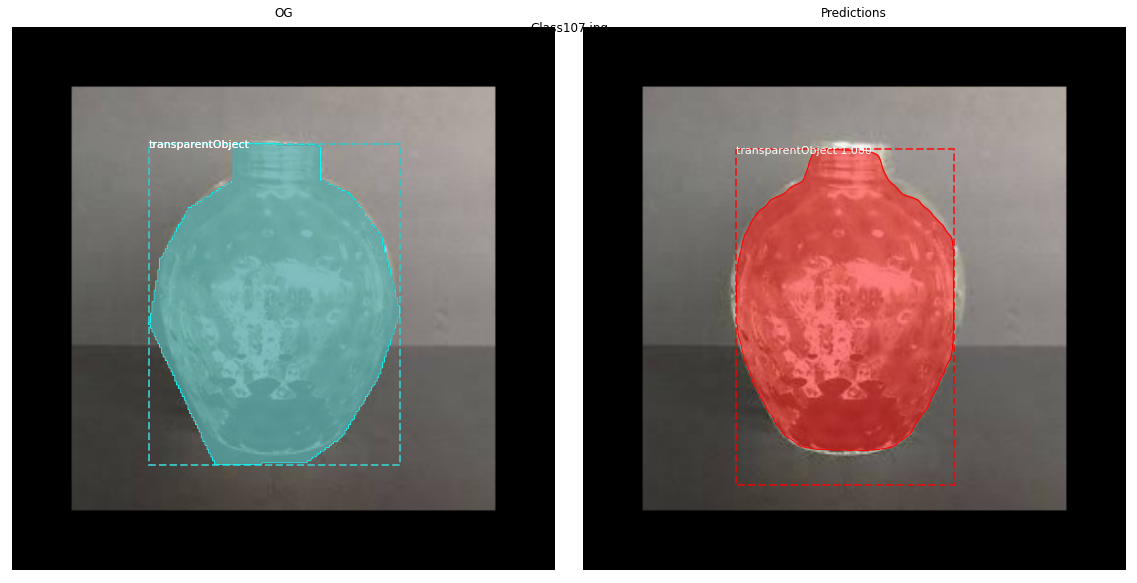

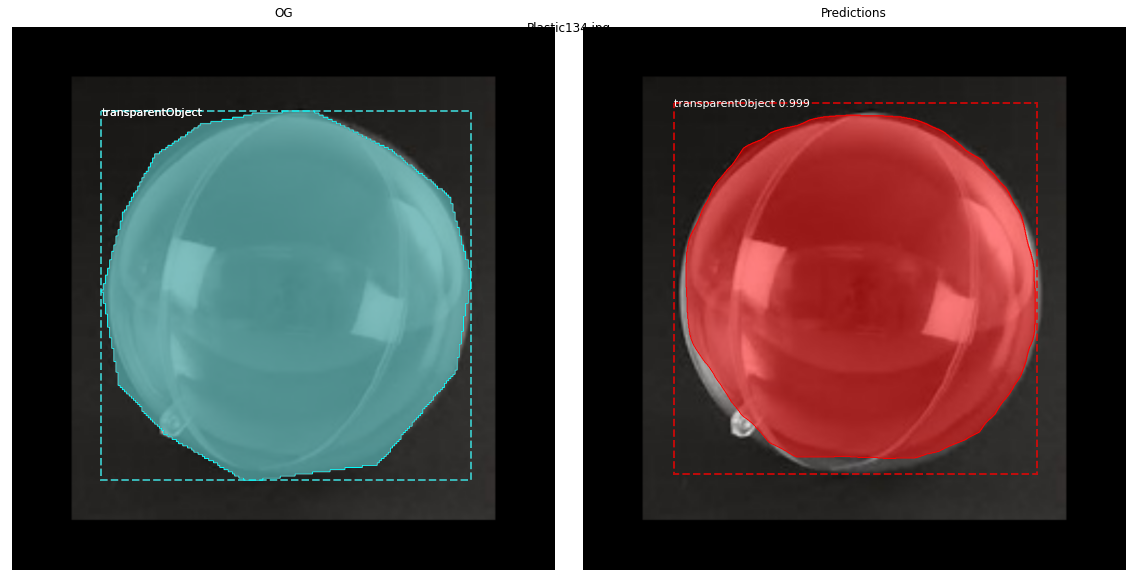

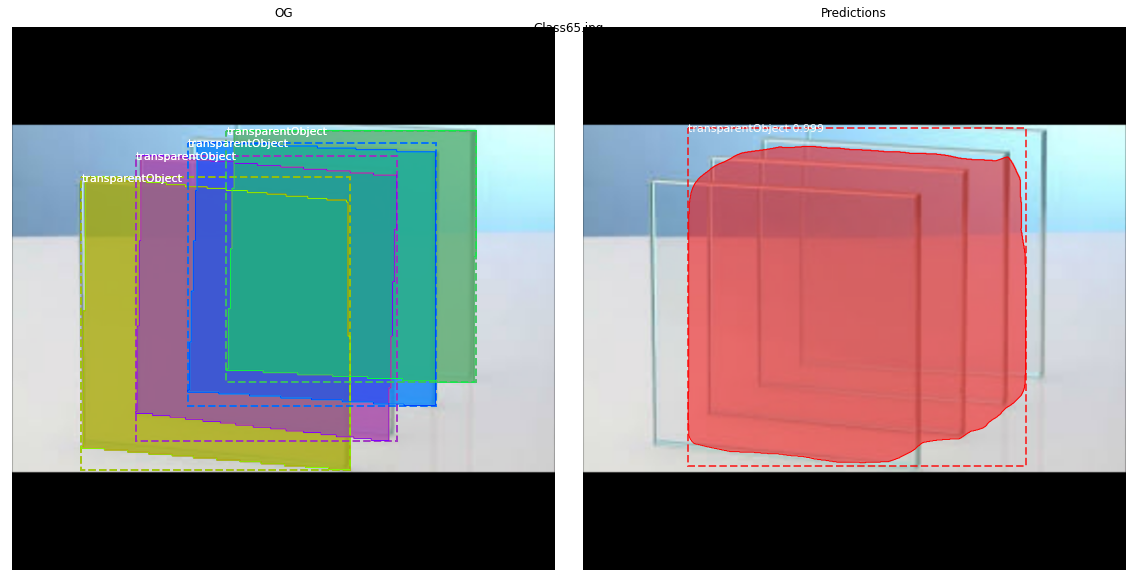

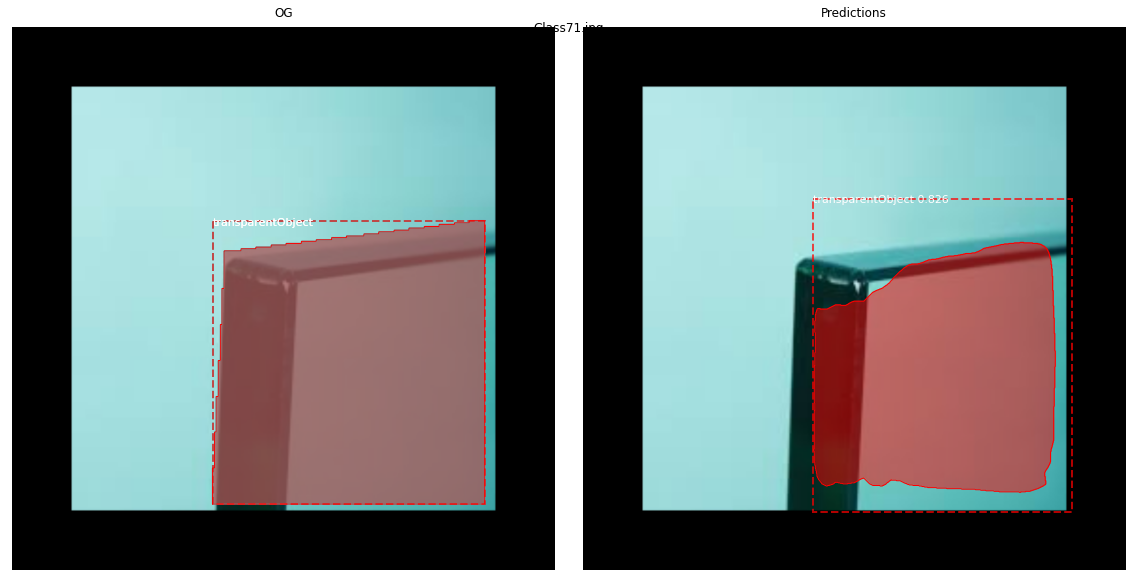

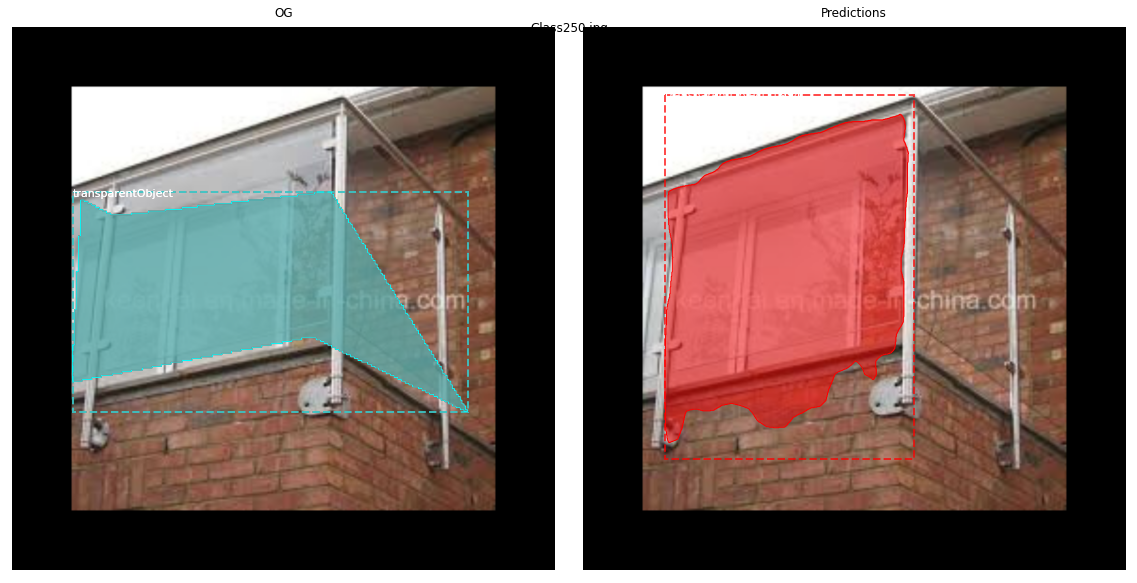

In [ ]:
for image_id in np.random.choice(dataset_test.image_ids, 5):
  # Test on a random image
  # image_id = np.random.choice(dataset_val.image_ids)
  _ = detectObjectsInImage(image_id, model_infer, dataset_val, verbose=0, visualizeImage=True)

**RUN THIS DURING PRESENTATION:**

In [ ]:
for image_id in np.random.choice(dataset_test.image_ids, 5):
  # Test on a random image
  # image_id = np.random.choice(dataset_val.image_ids)
  _ = detectObjectsInImage(image_id, model_infer, dataset_val, verbose=0, visualizeImage=True)

# Evaluation

## Plot mAP for all epochs.

In [ ]:
def computemAvgPrecision(model_infer, dataset, k=30):
  """ Compute VOC-Style mAP (AP = Avg Precision) by running on k images """
  image_ids = np.random.choice(dataset.image_ids, k)
  APs = []
  for image_id in image_ids:
      
      AP, precisions, recalls, overlaps = detectObjectsInImage(image_id, model_infer, dataset)
      APs.append(AP)  
  return np.mean(APs)

In [ ]:
print("mAP val dataset: ", computemAvgPrecision(model_infer, dataset_val,100))
print("mAP test dataset: ", computemAvgPrecision(model_infer, dataset_test,100))


mAP val dataset:  0.38366105798631905
mAP test dataset:  0.3915922622879346


In [ ]:
def plotmAvgPrecisionAcrossEpochs(num_epochs, model_infer, model_dir, dataset_val):
  mAPs = np.zeros(num_epochs)
  epochs = range(1,num_epochs+1)
  
  for epoch in epochs:
    epoch_str = str(epoch)
    if epoch < 10: # pad a zero to make 2 digits.
      epoch_str = epoch_str.zfill(2)
    model_path = os.path.join(model_dir, "mask_rcnn_transparentobj_00"+epoch_str+".h5")
    model_infer.load_weights(model_path, by_name=True)
    mAPs[epoch-1] = computemAvgPrecision(model_infer, dataset_val)

  plt.plot(epochs, mAPs, linestyle='-', marker='o', color='b', markerfacecolor='r', markeredgecolor='r')
  plt.xlabel("epoch")
  plt.ylabel("mAP")
  plt.title("m-Average Precision per epoch")
  plt.show()

Re-starting from epoch 1

Re-starting from epoch 2
Re-starting from epoch 3
Re-starting from epoch 4
Re-starting from epoch 5
Re-starting from epoch 6
Re-starting from epoch 7
Re-starting from epoch 8
Re-starting from epoch 9
Re-starting from epoch 10
Re-starting from epoch 11
Re-starting from epoch 12
Re-starting from epoch 13
Re-starting from epoch 14
Re-starting from epoch 15
Re-starting from epoch 16
Re-starting from epoch 17
Re-starting from epoch 18
Re-starting from epoch 19
Re-starting from epoch 20
Re-starting from epoch 21
Re-starting from epoch 22
Re-starting from epoch 23
Re-starting from epoch 24
Re-starting from epoch 25
Re-starting from epoch 26
Re-starting from epoch 27
Re-starting from epoch 28
Re-starting from epoch 29
Re-starting from epoch 30
Re-starting from epoch 31
Re-starting from epoch 32
Re-starting from epoch 33
Re-starting from epoch 34
Re-starting from epoch 35
Re-starting from epoch 36
Re-starting from epoch 37
Re-starting from epoch 38
Re-starting from epo

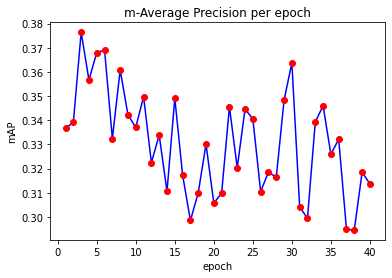

In [ ]:
model_path = os.path.join(MODEL_DIR, "transparentobj20210407T1018")
plotmAvgPrecisionAcrossEpochs(40, model_infer, model_path,dataset_val)

## Loss Per Epoch - Tensorboard

In [ ]:
%load_ext tensorboard

In [ ]:
%tensorboard --logdir /content/drive/MyDrive/Colab\ Notebooks/COMP592_Transaprent_Obj_Detection/logs/mask/transparentobj20210407T1018